# Support Vector Machine — Step-by-Step Implementation
### Predicting Financial Crises with the Jordà-Schularick-Taylor (JST) Macrohistory Database (R6)

**Problem:** Can we predict a **systemic financial crisis in the next 2 years** for a country, using its macro-financial conditions today?

The dataset (`JSTdatasetR6`) is a panel of **18 advanced economies, 1870–2020**, with 59 variables (GDP, credit, interest rates, house prices, equity returns, banking-sector ratios, ...) and a crisis indicator `crisisJST`.

This notebook follows the SVM implementation steps from the lecture:

| Step | What we do |
|---|---|
| **1. Data Preparation** | Data cleaning (missing values, outliers), feature engineering, feature scaling, train-test split |
| **2. Model Selection** | Choose kernel (linear vs non-linear), set hyperparameters C, γ, degree |
| **3. Training Process** | Solve the optimisation problem → find **w, b**, identify **support vectors**, store model parameters |
| **4. Model Validation** | K-fold cross-validation, grid search, metrics (Accuracy, Precision, Recall, AUROC, F1; and MSE, MAE, R² for SVR) |
| **Hyperparameter Tuning** | Effect of C (bias/variance), kernel choice, γ (boundary smoothness) |
| **5. Model Interpretation** | Support-vector analysis, feature importance from coefficients, 2D / 3D decision-boundary visualisation |

## 0. Setup

In [1]:
# If running in a fresh environment (e.g. Colab), uncomment:
# !pip install numbers-parser scikit-learn pandas matplotlib seaborn joblib

import warnings, json
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import (train_test_split, StratifiedKFold, KFold,
                                     cross_validate, GridSearchCV, validation_curve)
from sklearn.svm import SVC, SVR
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay, mean_squared_error, mean_absolute_error, r2_score)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

# Plot styling: one consistent palette for the whole notebook
C_NO, C_YES = "#2a78d6", "#eb6834"          # No crisis = blue, Crisis = orange
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "axes.edgecolor": INK2, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": INK2, "ytick.color": INK2, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "font.size": 10, "lines.linewidth": 2,
})

### Load the data
The file is an Apple Numbers spreadsheet, read with `numbers-parser`. (A CSV copy is used if it exists.)

In [2]:
from pathlib import Path

NUMBERS_PATH = Path("data/JSTdatasetR6.numbers")
CSV_PATH = Path("data/JSTdatasetR6.csv")

if CSV_PATH.exists():
    raw = pd.read_csv(CSV_PATH)
else:
    from numbers_parser import Document
    table = Document(NUMBERS_PATH).sheets[0].tables[0]
    rows = table.rows(values_only=True)
    raw = pd.DataFrame(rows[1:], columns=rows[0])

raw = raw.dropna(subset=["year"]).copy()     # drop the empty trailing row
raw["year"] = raw["year"].astype(int)
print("Shape:", raw.shape)
print("Countries:", raw["country"].nunique(), "|", ", ".join(sorted(raw["country"].unique())))
print("Years:", raw["year"].min(), "-", raw["year"].max())
raw.head()

Shape: (2718, 59)
Countries: 18 | Australia, Belgium, Canada, Denmark, Finland, France, Germany, Ireland, Italy, Japan, Netherlands, Norway, Portugal, Spain, Sweden, Switzerland, UK, USA
Years: 1870 - 2020


,year,country,iso,ifs,pop,rgdpmad,rgdpbarro,rconsbarro,gdp,iy,cpi,ca,imports,exports,narrowm,money,stir,ltrate,hpnom,unemp,wage,debtgdp,revenue,expenditure,xrusd,tloans,tmort,thh,tbus,bdebt,lev,ltd,noncore,crisisJST,crisisJST_old,peg,peg_strict,peg_type,peg_base,JSTtrilemmaIV,eq_tr,housing_tr,bond_tr,bill_rate,rent_ipolated,housing_capgain_ipolated,housing_capgain,housing_rent_rtn,housing_rent_yd,eq_capgain,eq_dp,eq_capgain_interp,eq_tr_interp,eq_dp_interp,bond_rate,eq_div_rtn,capital_tr,risky_tr,safe_tr
0,1870,Australia,AUS,193.0,1775.0,3273.239437,13.836157,21.449734,208.78,0.109266,2.708333,-6.147594,36.0,37.0,23.3,54.3,4.88,4.911817,0.492253,NaN,0.448118,0.172568,NaN,NaN,0.366946,54.792,1.680,NaN,NaN,NaN,25.016659,119.832039,32.928768,0.0,0.0,1.0,1.0,PEG,GBR,NaN,-0.004904,NaN,NaN,0.0488,NaN,NaN,NaN,NaN,NaN,-0.070045,0.071417,NaN,NaN,NaN,0.049118,0.066415,NaN,NaN,NaN
1,1871,Australia,AUS,193.0,1675.0,3298.507463,13.936864,19.930801,211.56,0.104579,2.666667,5.260774,34.0,46.0,27.2,59.5,4.60,4.844633,0.469877,NaN,0.439417,0.191799,NaN,NaN,0.369146,53.748,1.766,NaN,NaN,NaN,23.983004,107.037880,30.213655,0.0,0.0,1.0,1.0,PEG,GBR,-0.42,0.110193,NaN,NaN,0.0460,NaN,NaN,-0.045456,NaN,NaN,0.041654,0.065466,NaN,NaN,NaN,0.048446,0.068193,NaN,NaN,NaN
2,1872,Australia,AUS,193.0,1722.0,3553.426249,15.044247,21.085006,227.40,0.130438,2.541667,7.867636,38.0,53.0,36.2,68.5,4.60,4.737350,0.484794,NaN,0.452469,0.154920,NaN,NaN,0.369239,55.822,1.470,NaN,NaN,NaN,22.445646,94.909546,26.860411,0.0,0.0,1.0,1.0,PEG,GBR,1.27,0.176749,NaN,NaN,0.0460,NaN,NaN,0.031747,NaN,NaN,0.108945,0.062997,NaN,NaN,NaN,0.047373,0.069861,NaN,NaN,NaN
3,1873,Australia,AUS,193.0,1769.0,3823.629169,16.219443,23.254910,266.54,0.124986,2.541667,-11.047833,49.0,50.0,38.6,73.7,4.40,4.671958,0.469877,NaN,0.491625,0.142692,NaN,NaN,0.362405,65.380,1.364,NaN,NaN,NaN,21.004997,101.708099,28.645016,0.0,0.0,1.0,1.0,PEG,GBR,0.59,0.151686,NaN,NaN,0.0440,NaN,NaN,-0.030770,NaN,NaN,0.083086,0.064484,NaN,NaN,NaN,0.046720,0.069842,NaN,NaN,NaN
4,1874,Australia,AUS,193.0,1822.0,3834.796926,16.268228,23.458050,287.58,0.141960,2.666667,-5.563959,49.0,54.0,37.9,79.3,4.50,4.653317,0.566836,NaN,0.509028,0.194322,NaN,NaN,0.372223,71.478,1.434,NaN,NaN,NaN,20.974375,102.079346,28.298048,0.0,0.0,1.0,1.0,PEG,GBR,-1.08,0.191481,NaN,NaN,0.0450,NaN,NaN,0.206350,NaN,NaN,0.119389,0.063503,NaN,NaN,NaN,0.046533,0.071085,NaN,NaN,NaN


In [3]:
print("crisisJST counts (1 = start of a systemic financial crisis):")
print(raw["crisisJST"].value_counts(dropna=False))
print(f"\nCrisis rate: {raw['crisisJST'].mean():.2%}  -> heavily imbalanced target")

crisisJST counts (1 = start of a systemic financial crisis):
crisisJST
0.0    2580
1.0      88
NaN      50
Name: count, dtype: int64

Crisis rate: 3.30%  -> heavily imbalanced target


---
## Step 1: Data Preparation
### 1a. Data Cleaning — missing values

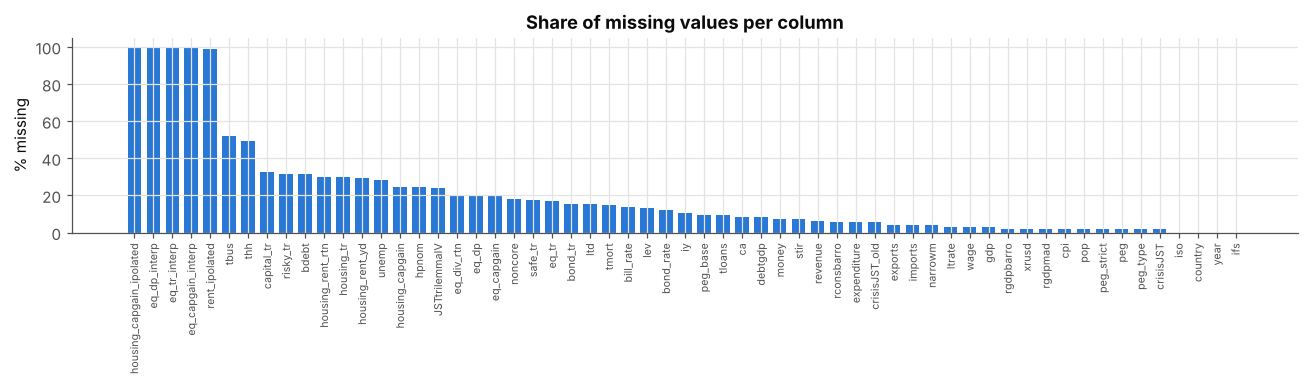

housing_capgain_ipolated    0.998
eq_dp_interp                0.998
eq_tr_interp                0.997
eq_capgain_interp           0.997
rent_ipolated               0.989
tbus                        0.522
thh                         0.494
capital_tr                  0.327
risky_tr                    0.318
bdebt                       0.314
housing_rent_rtn            0.298
housing_tr                  0.298


In [4]:
missing = raw.isna().mean().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(12, 3.6))
ax.bar(missing.index, missing.values * 100, color=C_NO, width=0.7)
ax.set_ylabel("% missing"); ax.set_title("Share of missing values per column")
ax.tick_params(axis="x", rotation=90, labelsize=7)
plt.tight_layout(); plt.show()
print(missing.head(12).round(3).to_string())

**Cleaning decisions**

1. Columns that are almost entirely empty (`*_ipolated`, `*_interp` flags, `thh`, `tbus` with ~50% missing) are dropped.
2. Nominal variables (GDP, loans, money, ...) are in **local currency** → not comparable across countries. They are converted to **ratios to GDP** or **growth rates** (feature engineering, below).
3. **World-war years** (1914-18, 1939-47) are excluded: hyperinflation and wartime controls produce extreme outliers (e.g. German equity returns of 10⁹ %).
4. Remaining gaps are filled with the **median** inside the model pipeline (fitted on training folds only → no leakage).
5. **Outliers** are **winsorised** at the 1st / 99th percentile, again inside the pipeline.

### 1b. Feature Engineering — create relevant features

Following the financial-crisis literature (Schularick & Taylor 2012; Bluwstein et al. 2023), the key predictors are **credit booms**, **asset-price booms**, the **yield-curve slope**, and **external imbalances**. All features are computed **within each country** (sorted by year).

In [5]:
df = raw.sort_values(["country", "year"]).copy()
g = df.groupby("country", group_keys=False)

# Credit & money relative to GDP
df["credit_gdp"]     = df["tloans"] / df["gdp"]
df["mort_gdp"]       = df["tmort"] / df["gdp"]
df["money_gdp"]      = df["money"] / df["gdp"]
df["d2_credit_gdp"]  = g["credit_gdp"].diff(2) * 100   # 2-year change in credit/GDP (pp)
df["d2_mort_gdp"]    = g["mort_gdp"].diff(2) * 100
df["d2_money_gdp"]   = g["money_gdp"].diff(2) * 100

# Real economy & prices
df["rgdp_growth"]    = g["rgdpbarro"].pct_change() * 100
df["inflation"]      = g["cpi"].pct_change() * 100
df["real_hp"]        = df["hpnom"] / df["cpi"]
df["d2_real_hp"]     = df.groupby("country")["real_hp"].pct_change(2) * 100  # real house-price growth
df["real_eq_return"] = (df["eq_tr"] * 100) - df["inflation"]               # real equity return

# Interest rates & external balance
df["slope"]          = df["ltrate"] - df["stir"]          # yield-curve slope
df["ca_gdp"]         = df["ca"] / df["gdp"] * 100         # current account / GDP
df["debtgdp_pct"]    = df["debtgdp"] * 100                # public debt / GDP
df["iy_pct"]         = df["iy"] * 100                     # investment / GDP

# Global credit boom: cross-country average credit growth in the same year
df["global_d2_credit"] = df.groupby("year")["d2_credit_gdp"].transform("mean")

# ---- Target: does a crisis START in the next 1 or 2 years? (early-warning set-up)
df["crisis_t1"] = g["crisisJST"].shift(-1)
df["crisis_t2"] = g["crisisJST"].shift(-2)
df["crisis_next2"] = df[["crisis_t1", "crisis_t2"]].max(axis=1, skipna=False)

FEATURES = ["d2_credit_gdp", "d2_mort_gdp", "d2_money_gdp", "global_d2_credit",
            "rgdp_growth", "inflation", "d2_real_hp", "real_eq_return",
            "slope", "stir", "ca_gdp", "debtgdp_pct", "iy_pct",
            "lev", "ltd", "noncore"]
TARGET = "crisis_next2"
FEATURE_LABELS = {
    "d2_credit_gdp": "Credit/GDP change (2y)", "d2_mort_gdp": "Mortgage/GDP change (2y)",
    "d2_money_gdp": "Money/GDP change (2y)", "global_d2_credit": "Global credit change (2y)",
    "rgdp_growth": "Real GDP growth", "inflation": "Inflation",
    "d2_real_hp": "Real house-price growth (2y)", "real_eq_return": "Real equity return",
    "slope": "Yield-curve slope", "stir": "Short-term rate", "ca_gdp": "Current account/GDP",
    "debtgdp_pct": "Public debt/GDP", "iy_pct": "Investment/GDP",
    "lev": "Bank capital ratio", "ltd": "Loan-to-deposit ratio", "noncore": "Non-core funding",
}
print(len(FEATURES), "engineered features")

16 engineered features


### 1c. Build the modelling sample

In [6]:
war_years = set(range(1914, 1919)) | set(range(1939, 1948))

model_df = df[
    df[TARGET].notna()                       # need the future 2 years to define the target
    & ~df["year"].isin(war_years)            # drop war-time outliers
    & (df["crisisJST"] != 1)                 # drop years already in a crisis start (not "early warning")
].copy()

# drop rows where more than half of the features are missing (no reliable information)
model_df = model_df[model_df[FEATURES].isna().mean(axis=1) <= 0.5]
model_df[TARGET] = model_df[TARGET].astype(int)

print("Modelling sample:", model_df.shape[0], "country-years")
print(model_df[TARGET].value_counts().rename({0: "No crisis ahead", 1: "Crisis in next 2y"}))
print(f"Positive rate: {model_df[TARGET].mean():.2%}")
print("\nRemaining missing share per feature:")
print(model_df[FEATURES].isna().mean().round(3).sort_values(ascending=False).to_string())

Modelling sample: 2250 country-years
crisis_next2
No crisis ahead      2083
Crisis in next 2y     167
Name: count, dtype: int64
Positive rate: 7.42%

Remaining missing share per feature:
d2_real_hp          0.226
real_eq_return      0.148
noncore             0.145
d2_mort_gdp         0.124
ltd                 0.120
lev                 0.103
d2_credit_gdp       0.069
d2_money_gdp        0.056
iy_pct              0.056
slope               0.048
debtgdp_pct         0.044
stir                0.043
ca_gdp              0.031
global_d2_credit    0.005
rgdp_growth         0.001
inflation           0.001


### 1d. Outliers — look before treating

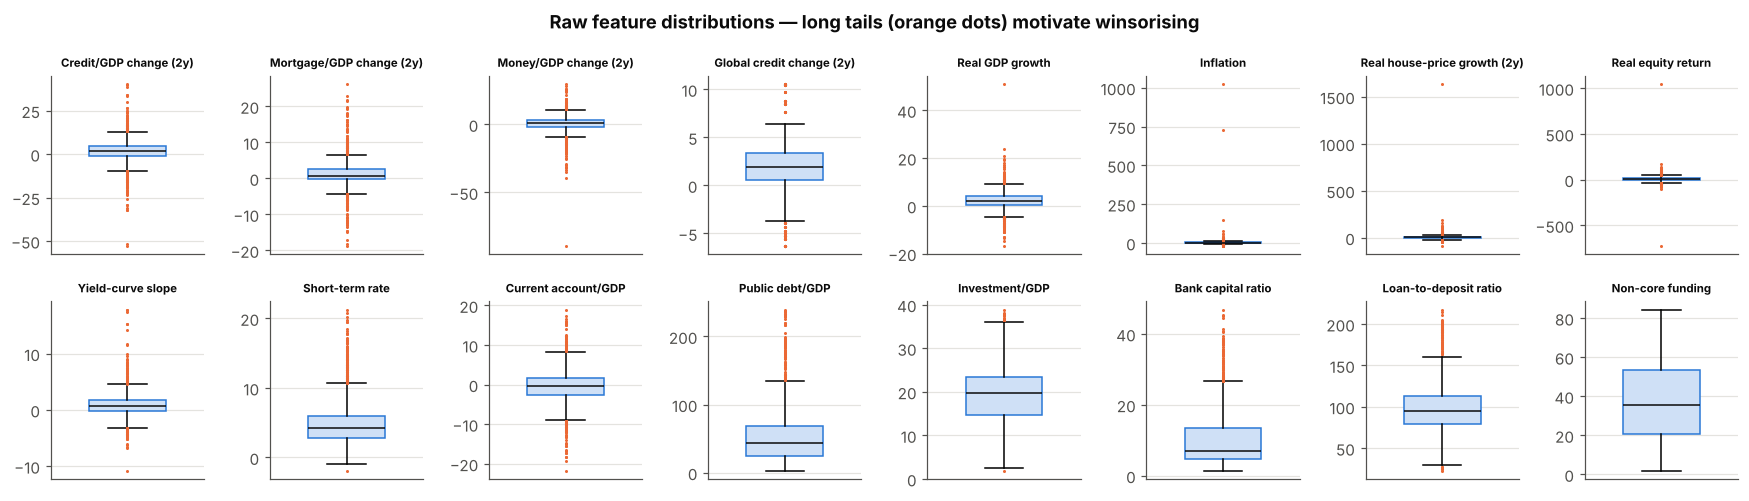

In [7]:
fig, axes = plt.subplots(2, 8, figsize=(16, 4.6))
for ax, f in zip(axes.ravel(), FEATURES):
    ax.boxplot(model_df[f].dropna(), widths=0.5, patch_artist=True,
               boxprops=dict(facecolor="#cfe0f6", color=C_NO), medianprops=dict(color=INK),
               flierprops=dict(marker="o", markersize=2, markerfacecolor=C_YES, markeredgecolor="none"))
    ax.set_title(FEATURE_LABELS[f], fontsize=7.5); ax.set_xticks([])
fig.suptitle("Raw feature distributions — long tails (orange dots) motivate winsorising", fontweight="bold")
plt.tight_layout(); plt.show()

Define a **Winsorizer** transformer: it learns the 1st/99th percentiles **on the training data only** and clips every feature to that range. It lives inside the pipeline so cross-validation stays leak-free.

In [8]:
class Winsorizer(BaseEstimator, TransformerMixin):
    # Clip each column to [q_low, q_high] quantiles learned at fit time
    def __init__(self, q_low=0.01, q_high=0.99):
        self.q_low, self.q_high = q_low, q_high
    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        self.low_ = np.nanquantile(X, self.q_low, axis=0)
        self.high_ = np.nanquantile(X, self.q_high, axis=0)
        return self
    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.low_, self.high_)

def make_preprocessor():
    return [("winsor", Winsorizer(0.01, 0.99)),
            ("impute", SimpleImputer(strategy="median")),
            ("scale", StandardScaler())]

### 1e. Feature Scaling — why it matters for SVM
SVM maximises a **geometric margin**, so a feature measured in large units would dominate the distance. Standardisation gives every feature mean 0 and standard deviation 1.

In [9]:
pre = Pipeline(make_preprocessor())
scaled = pd.DataFrame(pre.fit_transform(model_df[FEATURES]), columns=FEATURES)
summary = pd.DataFrame({
    "raw std":    model_df[FEATURES].std(),
    "raw range":  model_df[FEATURES].max() - model_df[FEATURES].min(),
    "scaled mean": scaled.mean().round(3).values,
    "scaled std":  scaled.std().round(3).values,
})
summary.round(2)

,raw std,raw range,scaled mean,scaled std
d2_credit_gdp,6.53,93.02,-0.0,1.0
d2_mort_gdp,3.60,44.94,-0.0,1.0
d2_money_gdp,5.83,118.93,-0.0,1.0
global_d2_credit,3.05,16.85,0.0,1.0
rgdp_growth,3.72,67.78,-0.0,1.0
inflation,27.29,1043.13,-0.0,1.0
d2_real_hp,42.49,1722.07,-0.0,1.0
real_eq_return,36.73,1770.76,-0.0,1.0
slope,1.98,28.75,-0.0,1.0
stir,3.39,23.27,-0.0,1.0


### 1f. Train-Test Split — separate data for validation
Stratified 80/20 split so the rare crisis class is represented in both sets.

In [10]:
X = model_df[FEATURES]
y = model_df[TARGET]
meta = model_df[["country", "year"]]

X_train, X_test, y_train, y_test, meta_train, meta_test = train_test_split(
    X, y, meta, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

print(f"Train: {X_train.shape}, positives = {y_train.sum()} ({y_train.mean():.2%})")
print(f"Test : {X_test.shape}, positives = {y_test.sum()} ({y_test.mean():.2%})")

Train: (1800, 16), positives = 134 (7.44%)
Test : (450, 16), positives = 33 (7.33%)


---
## Step 2: Model Selection (Important Step)

### 2a. Choose Kernel: Linear vs Non-linear

| Kernel | $K(x, x')$ | Hyperparameters |
|---|---|---|
| Linear | $x^\top x'$ | C |
| RBF (Gaussian) | $\exp(-\gamma\lVert x-x'\rVert^2)$ | C, γ |
| Polynomial | $(\gamma\,x^\top x' + r)^d$ | C, γ, degree d |

Because crises are rare (~8%), every SVM uses `class_weight="balanced"` — errors on the crisis class are penalised more (C is scaled up for the minority class). We compare kernels with their **default hyperparameters** using 5-fold stratified CV and **AUROC** (threshold-free, robust to imbalance).

In [11]:
def svm_pipeline(**svc_kwargs):
    return Pipeline(make_preprocessor() + [
        ("svm", SVC(class_weight="balanced", random_state=RANDOM_STATE, **svc_kwargs))])

candidates = {
    "Linear":            svm_pipeline(kernel="linear", C=1.0),
    "RBF":               svm_pipeline(kernel="rbf", C=1.0, gamma="scale"),
    "Polynomial (d=2)":  svm_pipeline(kernel="poly", degree=2, C=1.0, gamma="scale"),
    "Polynomial (d=3)":  svm_pipeline(kernel="poly", degree=3, C=1.0, gamma="scale"),
}
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

rows = []
for name, pipe in candidates.items():
    res = cross_validate(pipe, X_train, y_train, cv=cv5,
                         scoring=["roc_auc", "f1", "recall", "precision"], return_train_score=True)
    rows.append({"Kernel": name,
                 "CV AUROC": res["test_roc_auc"].mean(), "± std": res["test_roc_auc"].std(),
                 "Train AUROC": res["train_roc_auc"].mean(),
                 "CV F1": res["test_f1"].mean(), "CV Recall": res["test_recall"].mean(),
                 "CV Precision": res["test_precision"].mean()})
kernel_cmp = pd.DataFrame(rows).set_index("Kernel").round(3)
kernel_cmp

,CV AUROC,± std,Train AUROC,CV F1,CV Recall,CV Precision
Kernel,,,,,,
Linear,0.773,0.024,0.802,0.254,0.732,0.154
RBF,0.800,0.046,0.974,0.295,0.537,0.204
Polynomial (d=2),0.681,0.054,0.879,0.244,0.477,0.165
Polynomial (d=3),0.736,0.044,0.964,0.316,0.395,0.264


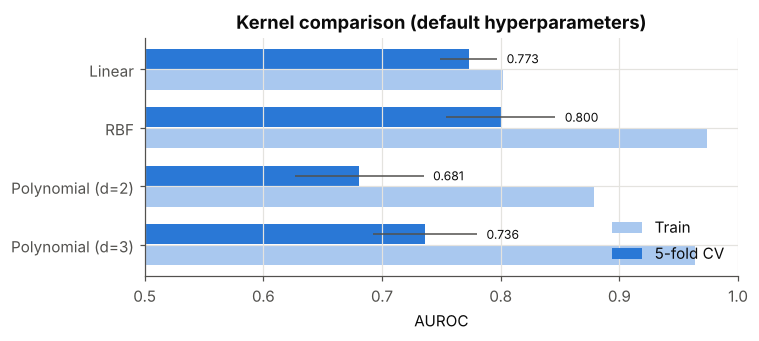

In [12]:
fig, ax = plt.subplots(figsize=(7, 3.2))
ypos = np.arange(len(kernel_cmp))
ax.barh(ypos + 0.18, kernel_cmp["Train AUROC"], height=0.34, color="#a9c8ef", label="Train")
ax.barh(ypos - 0.18, kernel_cmp["CV AUROC"], height=0.34, color=C_NO, label="5-fold CV",
        xerr=kernel_cmp["± std"], error_kw=dict(ecolor=INK2, lw=1))
ax.set_yticks(ypos, kernel_cmp.index); ax.invert_yaxis()
ax.set_xlim(0.5, 1.0); ax.set_xlabel("AUROC")
ax.set_title("Kernel comparison (default hyperparameters)")
ax.legend(loc="lower right", frameon=False)
for i, v in enumerate(kernel_cmp["CV AUROC"]):
    ax.text(v + kernel_cmp["± std"].iloc[i] + 0.008, i - 0.18, f"{v:.3f}", va="center", fontsize=8, color=INK)
plt.tight_layout(); plt.show()

**Reading the comparison:** the gap between train and CV AUROC is a direct view of **variance**. The linear kernel has the smallest gap (simple model, higher bias), while the non-linear kernels fit the training data more closely. The relationship between credit booms and crises is known to be non-linear (booms matter more when combined with, e.g., a flat yield curve), so a **non-linear (RBF) kernel** is our main candidate — the linear kernel is kept as an interpretable benchmark (its **w** gives feature importance in Step 5).

### 2b. Set Hyperparameters (initial values)
- **C (regularisation)** = 1.0 — starting point, tuned in Step 4
- **γ (RBF)** = `"scale"` = $1 / (n_\text{features}\cdot \mathrm{Var}(X))$ = 1/16 after standardisation
- **degree (polynomial)** = 2 or 3

These are refined with grid search in Step 4.

In [13]:
INITIAL_PARAMS = dict(kernel="rbf", C=1.0, gamma="scale")
print("Selected kernel for main model:", INITIAL_PARAMS)
print("gamma='scale' evaluates to:", 1 / (len(FEATURES) * 1.0))

Selected kernel for main model: {'kernel': 'rbf', 'C': 1.0, 'gamma': 'scale'}
gamma='scale' evaluates to: 0.0625


---
## Step 3: Training Process

### 3a. Solve the optimisation problem — find optimal w, b

The soft-margin SVM solves the **primal** problem

$$\min_{w,b,\xi}\; \frac12\lVert w\rVert^2 + C\sum_{i=1}^{n}\xi_i \quad \text{s.t.}\quad y_i(w^\top x_i + b)\ge 1-\xi_i,\;\; \xi_i\ge 0$$

In practice (libsvm / `SVC`) the **dual** is solved:

$$\max_{\alpha}\; \sum_i \alpha_i - \frac12\sum_{i,j}\alpha_i\alpha_j y_i y_j K(x_i,x_j)\quad\text{s.t.}\quad 0\le\alpha_i\le C,\;\; \sum_i\alpha_i y_i=0$$

and the decision function is $f(x) = \sum_{i\in SV}\alpha_i y_i K(x_i, x) + b$. For a **linear** kernel, $w = \sum_i \alpha_i y_i x_i$ explicitly.

We train both the **linear** SVM (to see w and b directly) and the selected **RBF** SVM.

In [14]:
linear_model = svm_pipeline(kernel="linear", C=1.0).fit(X_train, y_train)
rbf_model    = svm_pipeline(**INITIAL_PARAMS).fit(X_train, y_train)

lin_svc = linear_model.named_steps["svm"]
w = lin_svc.coef_.ravel()
b = lin_svc.intercept_[0]
print("Linear SVM  ->  w (one weight per standardised feature):")
print(pd.Series(w, index=FEATURES).round(4).to_string())
print(f"\nb = {b:.4f}")
print(f"||w|| = {np.linalg.norm(w):.4f}   ->  margin width 2/||w|| = {2/np.linalg.norm(w):.4f}")

Linear SVM  ->  w (one weight per standardised feature):
d2_credit_gdp       0.0919
d2_mort_gdp        -0.0056
d2_money_gdp        0.2895
global_d2_credit    0.4595
rgdp_growth         0.2332
inflation           0.0901
d2_real_hp          0.1482
real_eq_return     -0.3527
slope              -0.4092
stir                0.0931
ca_gdp             -0.2640
debtgdp_pct         0.1058
iy_pct             -0.4154
lev                 0.4113
ltd                 0.1335
noncore             0.0778

b = -0.4674
||w|| = 1.0653   ->  margin width 2/||w|| = 1.8774


**Verify the theory:** rebuild **w** from the dual solution $w=\sum_i \alpha_i y_i x_i$ and recompute $f(x)=w^\top x+b$ by hand.

In [15]:
Z_train_lin = Pipeline(linear_model.steps[:-1]).transform(X_train)   # preprocessed training data
alpha_y = lin_svc.dual_coef_.ravel()           # alpha_i * y_i for each support vector
w_from_dual = alpha_y @ lin_svc.support_vectors_

print("max |w_sklearn - w_from_dual| =", np.abs(w_from_dual - w).max())
f_manual  = Z_train_lin @ w + b
f_sklearn = lin_svc.decision_function(Z_train_lin)
print("max |f_manual - f_sklearn|    =", np.abs(f_manual - f_sklearn).max())
print("Constraint sum(alpha_i * y_i) =", round(alpha_y.sum(), 8), "(should be 0)")

max |w_sklearn - w_from_dual| = 0.0
max |f_manual - f_sklearn|    = 3.6060043839825084e-12
Constraint sum(alpha_i * y_i) = 0.0 (should be 0)


### 3b. Identify Support Vectors — the critical data points

In [16]:
def sv_summary(model, name):
    svc = model.named_steps["svm"]
    n_sv = svc.n_support_
    C_eff = svc.C * svc.class_weight_                 # effective C per class with balanced weights
    alpha = np.abs(svc.dual_coef_.ravel())
    sv_cls = y_train.values[svc.support_]
    at_bound = np.isclose(alpha, C_eff[sv_cls], rtol=1e-3)
    return {"Model": name,
            "SVs (no crisis)": n_sv[0], "SVs (crisis)": n_sv[1], "Total SVs": n_sv.sum(),
            "% of training set": f"{n_sv.sum() / len(y_train):.1%}",
            "% crisis obs that are SVs": f"{n_sv[1] / y_train.sum():.1%}",
            "Free SVs (on margin, 0<α<C)": int((~at_bound).sum()),
            "Bounded SVs (α=C, inside/wrong side)": int(at_bound.sum())}

pd.DataFrame([sv_summary(linear_model, "Linear, C=1"), sv_summary(rbf_model, "RBF, C=1")]).set_index("Model").T

Model,"Linear, C=1","RBF, C=1"
SVs (no crisis),1034,817
SVs (crisis),90,121
Total SVs,1124,938
% of training set,62.4%,52.1%
% crisis obs that are SVs,67.2%,90.3%
"Free SVs (on margin, 0<α<C)",18,210
"Bounded SVs (α=C, inside/wrong side)",1106,728


- **Free SVs** ($0<\alpha_i<C$) lie exactly **on** the margin ($y_i f(x_i)=1$) and define $b$.
- **Bounded SVs** ($\alpha_i=C$) are inside the margin or misclassified ($\xi_i>0$).
- All other points have $\alpha_i=0$ — removing them would not change the model at all.

With a hard, overlapping problem like crisis prediction, a large share of points become support vectors.

### 3c. Store Model Parameters — w, b, support vectors

In [17]:
Path("models").mkdir(exist_ok=True)

# Full fitted pipelines (preprocessing + SVM) -> can be reloaded and used for prediction
joblib.dump(linear_model, "models/svm_linear_initial.joblib")
joblib.dump(rbf_model, "models/svm_rbf_initial.joblib")

# Human-readable parameters of the linear SVM
params = {
    "kernel": "linear", "C": lin_svc.C, "features": FEATURES,
    "w": dict(zip(FEATURES, np.round(w, 6).tolist())), "b": round(float(b), 6),
    "n_support": lin_svc.n_support_.tolist(),
    "support_vector_indices": lin_svc.support_.tolist(),
    "scaler_mean": linear_model.named_steps["scale"].mean_.round(6).tolist(),
    "scaler_scale": linear_model.named_steps["scale"].scale_.round(6).tolist(),
}
with open("models/svm_linear_params.json", "w") as fh:
    json.dump(params, fh, indent=2)

# Support vectors of the RBF model (in standardised feature space) + which country-years they are
rbf_svc = rbf_model.named_steps["svm"]
sv_table = pd.DataFrame(rbf_svc.support_vectors_, columns=FEATURES)
sv_table.insert(0, "alpha_y", rbf_svc.dual_coef_.ravel())
sv_table.insert(0, "year", meta_train["year"].values[rbf_svc.support_])
sv_table.insert(0, "country", meta_train["country"].values[rbf_svc.support_])
sv_table.to_csv("models/svm_rbf_support_vectors.csv", index=False)

reloaded = joblib.load("models/svm_rbf_initial.joblib")
assert np.allclose(reloaded.decision_function(X_test), rbf_model.decision_function(X_test))
print("Saved files:", sorted(p.name for p in Path("models").iterdir()))
print("Reloaded model reproduces predictions ✔")
sv_table.head()

Saved files: ['svm_best_tuned.joblib', 'svm_linear_initial.joblib', 'svm_linear_params.json', 'svm_rbf_initial.joblib', 'svm_rbf_support_vectors.csv']
Reloaded model reproduces predictions ✔


,country,year,alpha_y,d2_credit_gdp,d2_mort_gdp,d2_money_gdp,global_d2_credit,rgdp_growth,inflation,d2_real_hp,real_eq_return,slope,stir,ca_gdp,debtgdp_pct,iy_pct,lev,ltd,noncore
0,Japan,1913,-0.540216,0.440788,-0.302689,-0.710619,-0.611662,-0.629506,0.045487,-0.071351,-0.578357,-2.645762,1.150316,-0.363535,0.040426,-0.388240,1.977299,0.898160,0.171174
1,Sweden,1998,-0.303616,-0.550635,-1.702847,-0.729549,0.932514,0.401810,-0.552730,1.273801,0.249462,0.006496,-0.209727,0.577790,0.459131,0.227775,-0.658997,-0.040388,1.139668
2,Japan,1885,-0.540216,-0.634161,-0.132725,-0.891642,0.620636,0.202581,-0.514985,-0.071351,-0.038038,-2.169018,1.318726,0.041514,-0.613575,-2.072946,-0.390311,-0.075981,-0.083276
3,Japan,1922,-0.540216,0.657894,1.093705,0.579550,1.935549,-1.160134,-0.807788,-0.080933,-0.543901,-2.706525,1.428959,-0.169121,-0.643486,-0.066714,1.342807,0.473291,0.005314
4,Belgium,1999,-0.540216,-0.288929,0.977181,2.014190,1.466774,0.174971,-0.309855,0.638546,-0.855386,0.685384,-0.625650,1.428521,1.798793,0.534473,-0.931353,0.404848,1.601457


---
## Step 4: Model Validation
### 4a. Cross-Validation — K-fold validation (K = 5 and K = 10)

In [18]:
scoring = {"Accuracy": "accuracy", "Precision": "precision", "Recall": "recall",
           "F1": "f1", "AUROC": "roc_auc"}

cv_rows = []
for k in (5, 10):
    cvk = StratifiedKFold(n_splits=k, shuffle=True, random_state=RANDOM_STATE)
    for name, model in [("Linear, C=1", svm_pipeline(kernel="linear", C=1.0)),
                        ("RBF, C=1, γ=scale", svm_pipeline(**INITIAL_PARAMS))]:
        res = cross_validate(model, X_train, y_train, cv=cvk, scoring=scoring)
        row = {"Model": name, "K": k}
        for m in scoring:
            row[m] = f"{res['test_' + m].mean():.3f} ± {res['test_' + m].std():.3f}"
        cv_rows.append(row)
pd.DataFrame(cv_rows).set_index(["Model", "K"])

,,Accuracy,Precision,Recall,F1,AUROC
Model,K,,,,,
"Linear, C=1",5,0.681 ± 0.009,0.154 ± 0.008,0.732 ± 0.057,0.254 ± 0.015,0.773 ± 0.024
"RBF, C=1, γ=scale",5,0.808 ± 0.016,0.204 ± 0.028,0.537 ± 0.055,0.295 ± 0.038,0.800 ± 0.046
"Linear, C=1",10,0.675 ± 0.028,0.153 ± 0.018,0.738 ± 0.093,0.253 ± 0.028,0.774 ± 0.054
"RBF, C=1, γ=scale",10,0.813 ± 0.028,0.223 ± 0.049,0.597 ± 0.112,0.324 ± 0.067,0.819 ± 0.057


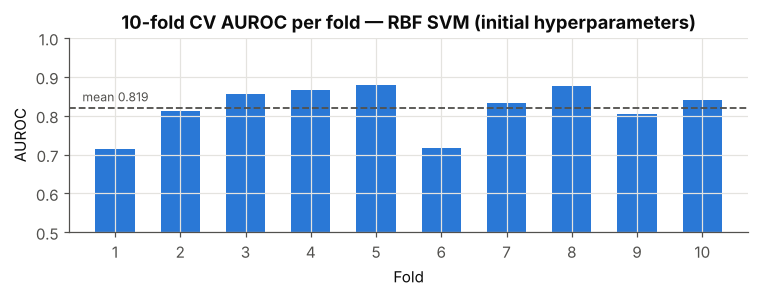

In [19]:
cv10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)
res = cross_validate(svm_pipeline(**INITIAL_PARAMS), X_train, y_train, cv=cv10, scoring="roc_auc")
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.bar(np.arange(1, 11), res["test_score"], color=C_NO, width=0.6)
ax.axhline(res["test_score"].mean(), color=INK2, ls="--", lw=1.2)
ax.text(0.5, res["test_score"].mean() + 0.01, f"mean {res['test_score'].mean():.3f}", va="bottom", ha="left", fontsize=8, color=INK2)
ax.set_xlim(0.3, 10.7)
ax.set_xticks(range(1, 11)); ax.set_xlabel("Fold"); ax.set_ylabel("AUROC"); ax.set_ylim(0.5, 1)
ax.set_title("10-fold CV AUROC per fold — RBF SVM (initial hyperparameters)")
plt.tight_layout(); plt.show()

### 4b. Grid Search — optimise hyperparameters
Exhaustive search over kernel, C, γ and degree, scored with 5-fold stratified CV AUROC. `refit=True` re-trains the best configuration on the full training set.

In [20]:
param_grid = [
    {"svm__kernel": ["linear"], "svm__C": [0.001, 0.01, 0.1, 1, 10]},
    {"svm__kernel": ["rbf"], "svm__C": [0.1, 1, 10, 100],
     "svm__gamma": [0.001, 0.01, 0.03, 0.1, 0.3, 1]},
    {"svm__kernel": ["poly"], "svm__C": [0.01, 0.1, 1, 10], "svm__degree": [2, 3],
     "svm__gamma": ["scale"], "svm__coef0": [1]},
]
grid = GridSearchCV(svm_pipeline(), param_grid, cv=cv5, scoring=scoring, refit="AUROC",
                    n_jobs=-1, return_train_score=True)
grid.fit(X_train, y_train)

print("Best hyperparameters:", grid.best_params_)
print(f"Best 5-fold CV AUROC: {grid.best_score_:.4f}")

gs = pd.DataFrame(grid.cv_results_)
cols = ["param_svm__kernel", "param_svm__C", "param_svm__gamma", "param_svm__degree",
        "mean_test_AUROC", "std_test_AUROC", "mean_train_AUROC", "mean_test_F1", "mean_test_Recall"]
gs[cols].sort_values("mean_test_AUROC", ascending=False).head(10).round(3)

Best hyperparameters: {'svm__C': 0.1, 'svm__coef0': 1, 'svm__degree': 2, 'svm__gamma': 'scale', 'svm__kernel': 'poly'}
Best 5-fold CV AUROC: 0.8245


,param_svm__kernel,param_svm__C,param_svm__gamma,param_svm__degree,mean_test_AUROC,std_test_AUROC,mean_train_AUROC,mean_test_F1,mean_test_Recall
31,poly,0.10,scale,2.0,0.824,0.037,0.888,0.320,0.776
32,poly,0.10,scale,3.0,0.820,0.041,0.938,0.319,0.663
18,rbf,10.00,0.01,NaN,0.819,0.037,0.925,0.330,0.731
13,rbf,1.00,0.03,NaN,0.814,0.038,0.925,0.315,0.708
30,poly,0.01,scale,3.0,0.813,0.042,0.876,0.300,0.612
23,rbf,100.00,0.001,NaN,0.810,0.036,0.869,0.283,0.746
12,rbf,1.00,0.01,NaN,0.810,0.037,0.865,0.284,0.761
33,poly,1.00,scale,2.0,0.803,0.032,0.926,0.304,0.664
29,poly,0.01,scale,2.0,0.797,0.039,0.833,0.275,0.671
7,rbf,0.10,0.03,NaN,0.794,0.037,0.849,0.267,0.754


In [21]:
best_by_kernel = (gs.sort_values("mean_test_AUROC", ascending=False)
                    .groupby("param_svm__kernel").head(1)
                    [["param_svm__kernel", "param_svm__C", "param_svm__gamma", "param_svm__degree",
                      "mean_test_AUROC", "mean_train_AUROC"]].round(3))
best_by_kernel.columns = ["Kernel", "C", "γ", "degree", "CV AUROC", "Train AUROC"]
best_by_kernel.set_index("Kernel")

,C,γ,degree,CV AUROC,Train AUROC
Kernel,,,,,
poly,0.10,scale,2.0,0.824,0.888
rbf,10.00,0.01,NaN,0.819,0.925
linear,0.01,NaN,NaN,0.776,0.802


### 4c. Performance Metrics — Classification (held-out test set)

In [22]:
best_model = grid.best_estimator_
joblib.dump(best_model, "models/svm_best_tuned.joblib")

def evaluate(model, X_, y_):
    pred = model.predict(X_)
    score = model.decision_function(X_)
    return {"Accuracy": accuracy_score(y_, pred), "Precision": precision_score(y_, pred, zero_division=0),
            "Recall": recall_score(y_, pred), "F1": f1_score(y_, pred), "AUROC": roc_auc_score(y_, score)}

baseline = {"Accuracy": 1 - y_test.mean(), "Precision": 0.0, "Recall": 0.0, "F1": 0.0, "AUROC": 0.5}
test_tbl = pd.DataFrame({
    "Always 'no crisis' (baseline)": baseline,
    "Linear SVM (C=1)": evaluate(linear_model, X_test, y_test),
    "RBF SVM (initial)": evaluate(rbf_model, X_test, y_test),
    f"Tuned SVM ({grid.best_params_['svm__kernel']})": evaluate(best_model, X_test, y_test),
}).T.round(3)
test_tbl

,Accuracy,Precision,Recall,F1,AUROC
Always 'no crisis' (baseline),0.927,0.000,0.000,0.000,0.500
Linear SVM (C=1),0.638,0.131,0.697,0.220,0.702
RBF SVM (initial),0.791,0.172,0.485,0.254,0.765
Tuned SVM (poly),0.711,0.161,0.697,0.261,0.760


> **Choosing the model:** the final model is chosen by **cross-validated** AUROC (Step 4b), not by the test set. The test set has only 33 crisis cases, so test AUROC differences of ±0.01–0.02 between the tuned and initial models are within noise. The test set gives an honest, one-time estimate of performance.

> **Why accuracy is misleading here:** a model that *never* predicts a crisis already gets ~92% accuracy but catches zero crises. Recall (share of crises caught), precision, F1 and AUROC are the meaningful metrics for this imbalanced problem.

                   precision    recall  f1-score   support

  No crisis ahead      0.967     0.712     0.820       417
Crisis in next 2y      0.161     0.697     0.261        33

         accuracy                          0.711       450
        macro avg      0.564     0.705     0.541       450
     weighted avg      0.908     0.711     0.779       450



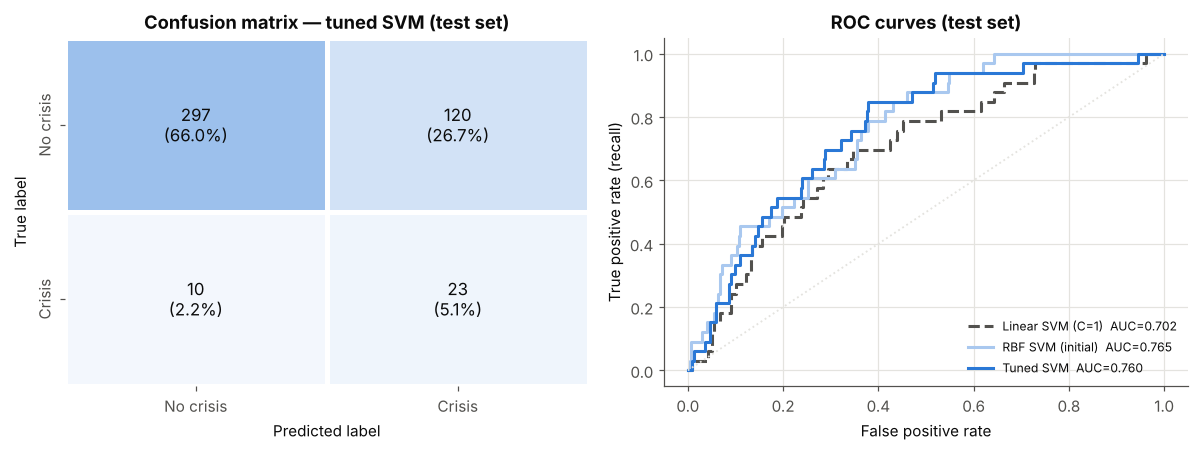

In [23]:
y_pred = best_model.predict(X_test)
print(classification_report(y_test, y_pred, target_names=["No crisis ahead", "Crisis in next 2y"], digits=3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
cm = confusion_matrix(y_test, y_pred)
cm_lab = np.array([[f"{v}\n({v / cm.sum():.1%})" for v in r] for r in cm])
sns.heatmap(cm, annot=cm_lab, fmt="", cbar=False, ax=axes[0], linewidths=2, linecolor="white",
            cmap=sns.blend_palette(["#f3f7fd", "#9cc0ec"], as_cmap=True), annot_kws=dict(color=INK, fontsize=11),
            xticklabels=["No crisis", "Crisis"], yticklabels=["No crisis", "Crisis"])
axes[0].set_xlabel("Predicted label"); axes[0].set_ylabel("True label")
axes[0].set_title("Confusion matrix — tuned SVM (test set)"); axes[0].grid(False)

for model, name, col, ls in [(linear_model, "Linear SVM (C=1)", INK2, "--"),
                             (rbf_model, "RBF SVM (initial)", "#a9c8ef", "-"),
                             (best_model, "Tuned SVM", C_NO, "-")]:
    s = model.decision_function(X_test)
    fpr, tpr, _ = roc_curve(y_test, s)
    axes[1].plot(fpr, tpr, color=col, ls=ls, label=f"{name}  AUC={roc_auc_score(y_test, s):.3f}")
axes[1].plot([0, 1], [0, 1], color=GRID, lw=1.2, ls=":")
axes[1].set_xlabel("False positive rate"); axes[1].set_ylabel("True positive rate (recall)")
axes[1].set_title("ROC curves (test set)"); axes[1].legend(frameon=False, loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

### 4d. Performance Metrics — Regression (Support Vector Regression)

The same SVM machinery works for regression (**SVR**, ε-insensitive loss). As a regression example we predict a country's **long-term government bond yield** (`ltrate`) from the short-term rate, inflation, growth, public debt and the current account — and report **MSE, MAE, R²**.

Best SVR params: {'svr__C': 10, 'svr__epsilon': 0.1, 'svr__gamma': 0.1, 'svr__kernel': 'rbf'}
MSE     3.539
RMSE    1.881
MAE     1.021
R²      0.661


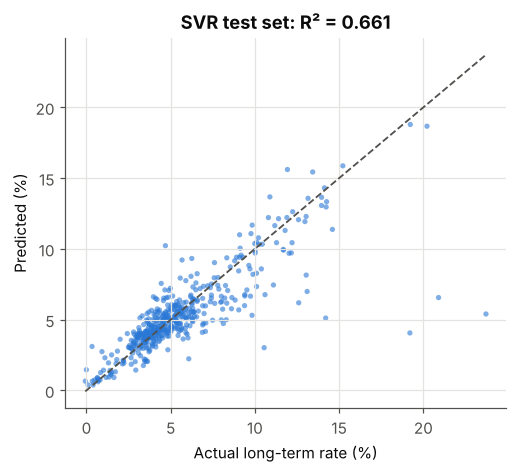

In [24]:
REG_FEATURES = ["stir", "inflation", "rgdp_growth", "debtgdp_pct", "ca_gdp", "d2_credit_gdp", "global_d2_credit"]
reg_df = df[~df["year"].isin(war_years)].dropna(subset=["ltrate"])
reg_df = reg_df[reg_df[REG_FEATURES].isna().mean(axis=1) <= 0.5]
Xr, yr = reg_df[REG_FEATURES], reg_df["ltrate"]
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(Xr, yr, test_size=0.2, random_state=RANDOM_STATE)

svr_grid = GridSearchCV(
    Pipeline(make_preprocessor() + [("svr", SVR())]),
    {"svr__kernel": ["linear", "rbf"], "svr__C": [0.1, 1, 10, 100], "svr__gamma": ["scale", 0.1, 0.3],
     "svr__epsilon": [0.1, 0.5]},
    cv=KFold(5, shuffle=True, random_state=RANDOM_STATE), scoring="neg_mean_squared_error", n_jobs=-1)
svr_grid.fit(Xr_tr, yr_tr)
yr_hat = svr_grid.predict(Xr_te)

print("Best SVR params:", svr_grid.best_params_)
reg_metrics = pd.Series({"MSE": mean_squared_error(yr_te, yr_hat),
                         "RMSE": np.sqrt(mean_squared_error(yr_te, yr_hat)),
                         "MAE": mean_absolute_error(yr_te, yr_hat),
                         "R²": r2_score(yr_te, yr_hat)}).round(3)
print(reg_metrics.to_string())

fig, ax = plt.subplots(figsize=(4.8, 4.4))
ax.scatter(yr_te, yr_hat, s=12, color=C_NO, alpha=0.6, edgecolor="none")
lim = [min(yr_te.min(), yr_hat.min()), max(yr_te.max(), yr_hat.max())]
ax.plot(lim, lim, color=INK2, lw=1.2, ls="--")
ax.set_xlabel("Actual long-term rate (%)"); ax.set_ylabel("Predicted (%)")
ax.set_title(f"SVR test set: R² = {reg_metrics['R²']:.3f}")
plt.tight_layout(); plt.show()

---
## Hyperparameter Tuning in SVM

### C (Regularisation Parameter)
- **Low C** → wide margin, many violations allowed → simple model, **higher bias, lower variance**
- **High C** → narrow margin, tries to classify every training point → complex model, **lower bias, higher variance**
- Idea: balance model complexity and generalisation → pick C where the **validation** score peaks.

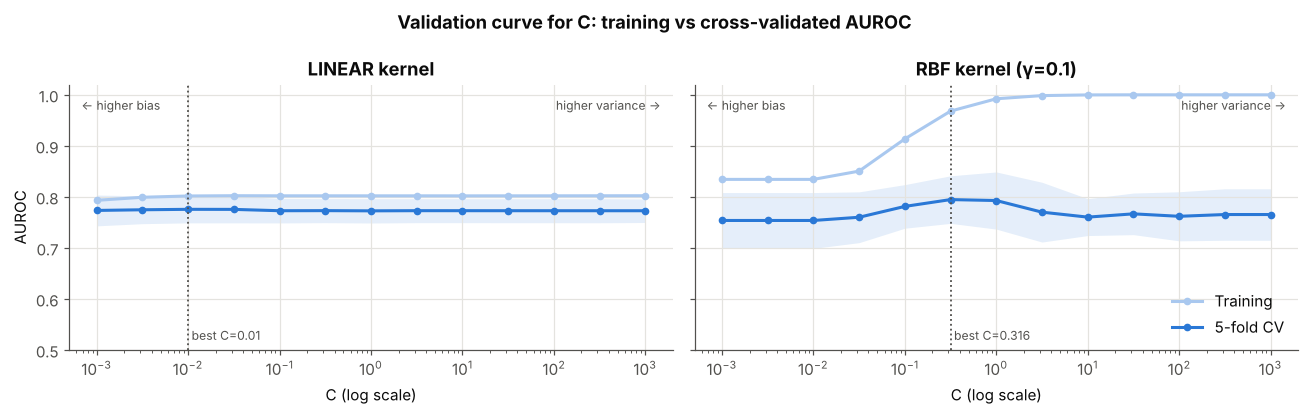

In [25]:
C_range = np.logspace(-3, 3, 13)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, (kname, extra) in zip(axes, [("linear", {}), ("rbf", {"svm__gamma": 0.1})]):
    pipe = svm_pipeline(kernel=kname)
    if extra: pipe.set_params(**extra)
    tr, va = validation_curve(pipe, X_train, y_train, param_name="svm__C", param_range=C_range,
                              cv=cv5, scoring="roc_auc", n_jobs=-1)
    ax.semilogx(C_range, tr.mean(1), color="#a9c8ef", marker="o", ms=4, label="Training")
    ax.semilogx(C_range, va.mean(1), color=C_NO, marker="o", ms=4, label="5-fold CV")
    ax.fill_between(C_range, va.mean(1) - va.std(1), va.mean(1) + va.std(1), color=C_NO, alpha=0.12, lw=0)
    best_c = C_range[va.mean(1).argmax()]
    ax.axvline(best_c, color=INK2, ls=":", lw=1.2)
    ax.text(best_c, 0.52, f" best C={best_c:.3g}", fontsize=8, color=INK2)
    ax.set_xlabel("C (log scale)"); ax.set_title(f"{kname.upper()} kernel" + (" (γ=0.1)" if extra else ""))
    ax.text(0.02, 0.95, "← higher bias", transform=ax.transAxes, fontsize=8, color=INK2, va="top")
    ax.text(0.98, 0.95, "higher variance →", transform=ax.transAxes, fontsize=8, color=INK2, va="top", ha="right")
axes[0].set_ylabel("AUROC"); axes[0].set_ylim(0.5, 1.02); axes[1].legend(frameon=False, loc="lower right")
fig.suptitle("Validation curve for C: training vs cross-validated AUROC", fontweight="bold")
plt.tight_layout(); plt.show()

### Kernel Selection
- **Linear:** when data is linearly separable or high-dimensional
- **RBF:** most common, good default choice
- **Polynomial:** for specific polynomial relationships

The best configuration of each kernel from the grid search:

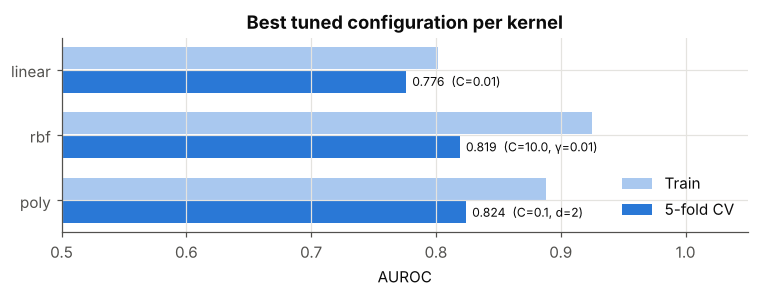

In [26]:
fig, ax = plt.subplots(figsize=(7, 2.8))
bk = best_by_kernel.set_index("Kernel")
yp = np.arange(len(bk))
ax.barh(yp + 0.18, bk["Train AUROC"], height=0.34, color="#a9c8ef", label="Train")
ax.barh(yp - 0.18, bk["CV AUROC"], height=0.34, color=C_NO, label="5-fold CV")
for i, (k, r) in enumerate(bk.iterrows()):
    cfg = f"C={r['C']}" + (f", γ={r['γ']}" if k == "rbf" else "") + (f", d={int(r['degree'])}" if k == "poly" else "")
    ax.text(r["CV AUROC"] + 0.005, i - 0.18, f"{r['CV AUROC']:.3f}  ({cfg})", va="center", fontsize=8)
ax.set_yticks(yp, bk.index); ax.set_xlim(0.5, 1.05); ax.set_xlabel("AUROC")
ax.set_title("Best tuned configuration per kernel"); ax.legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.show()

### Gamma (for RBF kernel)
γ controls how far the influence of a single training point reaches: $K(x,x') = e^{-\gamma\lVert x-x'\rVert^2}$.
- **Low γ** → smooth decision boundary, far-reaching influence
- **High γ** → tight decision boundary, close influence only (risk of overfitting)

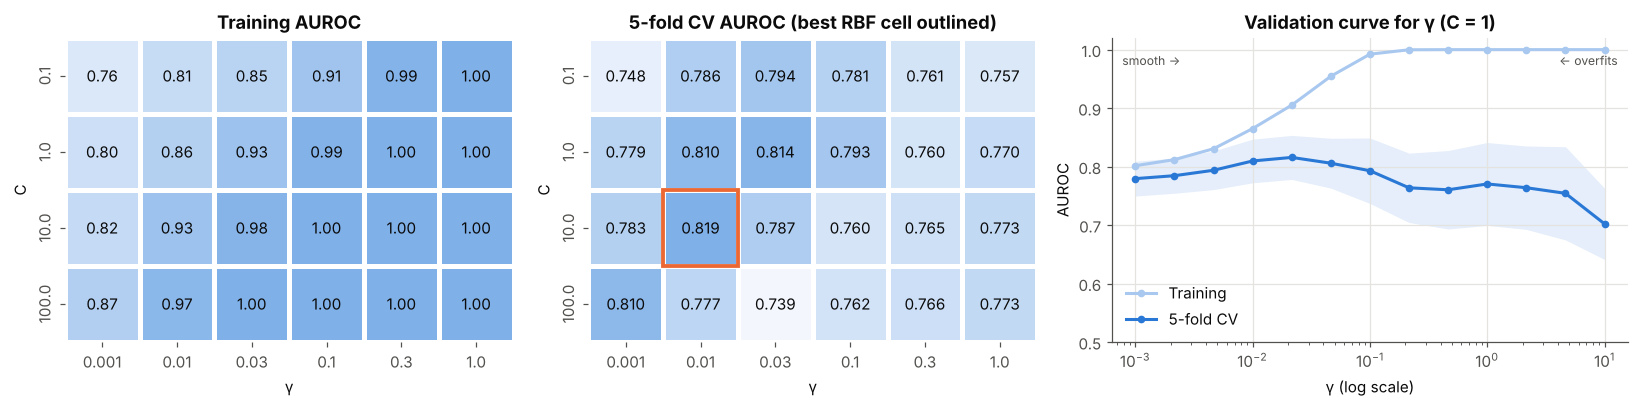

In [27]:
rbf_res = gs[gs["param_svm__kernel"] == "rbf"]
heat = rbf_res.pivot_table(index="param_svm__C", columns="param_svm__gamma", values="mean_test_AUROC")
heat_tr = rbf_res.pivot_table(index="param_svm__C", columns="param_svm__gamma", values="mean_train_AUROC")

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), gridspec_kw={"width_ratios": [1, 1, 1.15]})
cmap = sns.blend_palette(["#f3f7fd", "#7fb0e8"], as_cmap=True)
sns.heatmap(heat_tr, annot=True, fmt=".2f", cmap=cmap, vmin=0.7, vmax=1, ax=axes[0], cbar=False, linewidths=2,
            linecolor="white", annot_kws=dict(color=INK))
axes[0].set_title("Training AUROC"); axes[0].set_xlabel("γ"); axes[0].set_ylabel("C")
sns.heatmap(heat, annot=True, fmt=".3f", cmap=cmap, vmin=heat.values.min(), vmax=heat.values.max(), ax=axes[1],
            cbar=False, linewidths=2, linecolor="white", annot_kws=dict(color=INK))
best_idx = np.unravel_index(np.nanargmax(heat.values), heat.shape)
axes[1].add_patch(plt.Rectangle((best_idx[1], best_idx[0]), 1, 1, fill=False, edgecolor=C_YES, lw=2.5))
for a in axes[:2]: a.grid(False)
axes[1].set_title("5-fold CV AUROC (best RBF cell outlined)"); axes[1].set_xlabel("γ"); axes[1].set_ylabel("C")

g_range = np.logspace(-3, 1, 13)
tr, va = validation_curve(svm_pipeline(kernel="rbf", C=1), X_train, y_train, param_name="svm__gamma",
                          param_range=g_range, cv=cv5, scoring="roc_auc", n_jobs=-1)
axes[2].semilogx(g_range, tr.mean(1), color="#a9c8ef", marker="o", ms=4, label="Training")
axes[2].semilogx(g_range, va.mean(1), color=C_NO, marker="o", ms=4, label="5-fold CV")
axes[2].fill_between(g_range, va.mean(1) - va.std(1), va.mean(1) + va.std(1), color=C_NO, alpha=0.12, lw=0)
axes[2].set_xlabel("γ (log scale)"); axes[2].set_ylabel("AUROC"); axes[2].set_ylim(0.5, 1.02)
axes[2].set_title("Validation curve for γ (C = 1)"); axes[2].legend(frameon=False, loc="lower left")
axes[2].text(0.02, 0.95, "smooth →", transform=axes[2].transAxes, fontsize=8, color=INK2, va="top")
axes[2].text(0.98, 0.95, "← overfits", transform=axes[2].transAxes, fontsize=8, color=INK2, va="top", ha="right")
plt.tight_layout(); plt.show()

As γ (and C) grow, training AUROC approaches 1.0 while CV AUROC falls — the classic overfitting signature. The best region is moderate γ with moderate C.

---
## Step 5: Model Interpretation
### 5a. Support Vector Analysis — which points are critical?

In [28]:
best_svc = best_model.named_steps["svm"]
pre_best = Pipeline(best_model.steps[:-1])
Z_train = pre_best.transform(X_train)
f_train = best_model.decision_function(X_train)
is_sv = np.zeros(len(y_train), bool); is_sv[best_svc.support_] = True

print("Tuned model:", grid.best_params_)
print("Support vectors per class [no crisis, crisis]:", best_svc.n_support_,
      f"-> {is_sv.mean():.1%} of training points are support vectors")

margin = y_train.map({0: -1, 1: 1}).values * f_train   # y_i * f(x_i)
cats = pd.cut(margin, [-np.inf, 0, 1 - 1e-3, 1 + 1e-3, np.inf],
              labels=["Misclassified (y·f<0)", "Inside margin (0≤y·f<1)", "On margin (y·f=1)", "Outside margin (y·f>1)"])
pd.crosstab(cats, pd.Series(is_sv, name="Support vector?"), margins=True)

Tuned model: {'svm__C': 0.1, 'svm__coef0': 1, 'svm__degree': 2, 'svm__gamma': 'scale', 'svm__kernel': 'poly'}
Support vectors per class [no crisis, crisis]: [1002  100] -> 61.2% of training points are support vectors


Support vector?,False,True,All
row_0,,,
Misclassified (y·f<0),0,428,428
Inside margin (0≤y·f<1),0,616,616
On margin (y·f=1),3,58,61
Outside margin (y·f>1),695,0,695
All,698,1102,1800


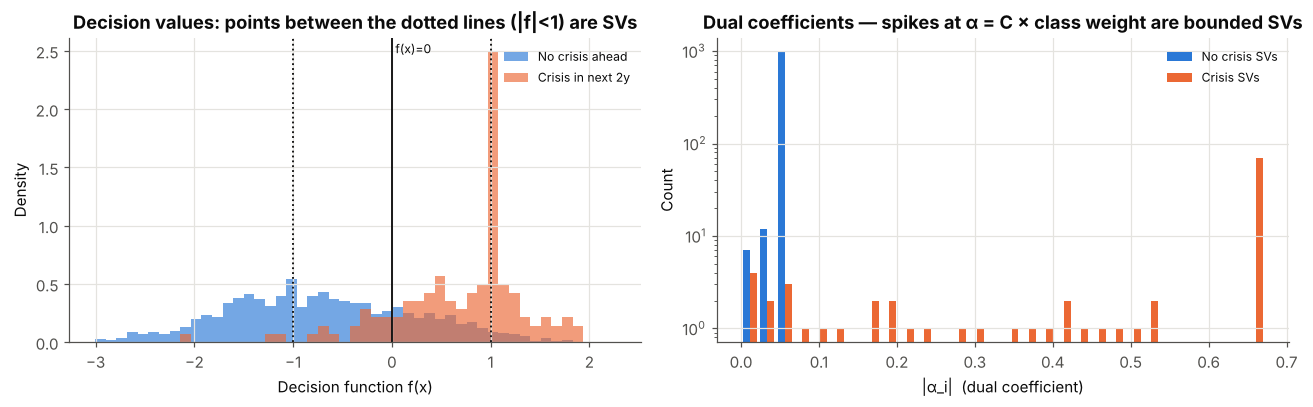

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
bins = np.linspace(np.percentile(f_train, 0.5), np.percentile(f_train, 99.5), 50)
for cls, col, lab in [(0, C_NO, "No crisis ahead"), (1, C_YES, "Crisis in next 2y")]:
    axes[0].hist(f_train[y_train.values == cls], bins=bins, color=col, alpha=0.65, label=lab, density=True)
for v, ls in [(-1, ":"), (0, "-"), (1, ":")]:
    axes[0].axvline(v, color=INK, ls=ls, lw=1.2)
axes[0].text(0, axes[0].get_ylim()[1] * 0.95, " f(x)=0", fontsize=8)
axes[0].set_xlabel("Decision function f(x)"); axes[0].set_ylabel("Density")
axes[0].set_title("Decision values: points between the dotted lines (|f|<1) are SVs")
axes[0].legend(frameon=False, fontsize=8)

alpha_abs = np.abs(best_svc.dual_coef_.ravel())
sv_cls = y_train.values[best_svc.support_]
axes[1].hist([alpha_abs[sv_cls == 0], alpha_abs[sv_cls == 1]], bins=30, color=[C_NO, C_YES],
             label=["No crisis SVs", "Crisis SVs"], stacked=False)
axes[1].set_xlabel("|α_i|  (dual coefficient)"); axes[1].set_ylabel("Count")
axes[1].set_yscale("log")
axes[1].set_title("Dual coefficients — spikes at α = C × class weight are bounded SVs"); axes[1].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

**Which crisis episodes are critical?** The crisis-class support vectors with the smallest (or wrong-signed) decision values are the episodes the model finds hardest — they sit closest to, or on the wrong side of, the boundary.

In [30]:
sv_info = meta_train.iloc[best_svc.support_].copy()
sv_info["y"] = y_train.values[best_svc.support_]
sv_info["f(x)"] = f_train[best_svc.support_]
sv_info["|alpha|"] = alpha_abs
sv_info = sv_info.join(X_train[["d2_credit_gdp", "slope", "d2_real_hp", "global_d2_credit"]])

print("Hardest pre-crisis observations (crisis-class SVs with lowest f(x)):")
display(sv_info[sv_info["y"] == 1].sort_values("f(x)").head(8).round(2))
print("Most 'crisis-like' calm years (no-crisis SVs with highest f(x) -> false alarms):")
display(sv_info[sv_info["y"] == 0].sort_values("f(x)", ascending=False).head(8).round(2))

Hardest pre-crisis observations (crisis-class SVs with lowest f(x)):


,country,year,y,f(x),|alpha|,d2_credit_gdp,slope,d2_real_hp,global_d2_credit
1938,Japan,1996,1,-2.11,0.67,-3.23,1.76,-3.35,0.42
2680,USA,1983,1,-1.21,0.67,0.92,2.02,-2.96,0.52
2679,USA,1982,1,-1.11,0.67,-2.89,0.76,-6.52,1.32
1225,France,1887,1,-0.80,0.67,NaN,1.28,0.39,2.17
2283,Portugal,1888,1,-0.73,0.67,0.36,0.21,NaN,1.39
1219,France,1881,1,-0.65,0.67,NaN,-0.10,15.01,2.03
1218,France,1880,1,-0.62,0.67,NaN,1.01,22.37,0.68
605,Germany,1871,1,-0.33,0.67,NaN,0.33,NaN,NaN


Most 'crisis-like' calm years (no-crisis SVs with highest f(x) -> false alarms):


,country,year,y,f(x),|alpha|,d2_credit_gdp,slope,d2_real_hp,global_d2_credit
1839,Japan,1897,0,3.13,0.05,3.79,-6.54,NaN,1.76
1872,Japan,1930,0,3.07,0.05,8.74,-1.39,-13.56,4.15
1873,Japan,1931,0,2.95,0.05,16.68,-1.60,NaN,6.41
1864,Japan,1922,0,2.52,0.05,5.23,-3.78,3.70,7.65
1840,Japan,1898,0,2.40,0.05,-3.85,-6.19,NaN,0.70
138,Australia,2008,0,2.27,0.05,19.83,-0.85,8.79,9.74
916,Spain,1880,0,2.26,0.05,NaN,11.78,NaN,0.68
658,Germany,1924,0,1.89,0.05,NaN,-3.14,1634.33,-3.36


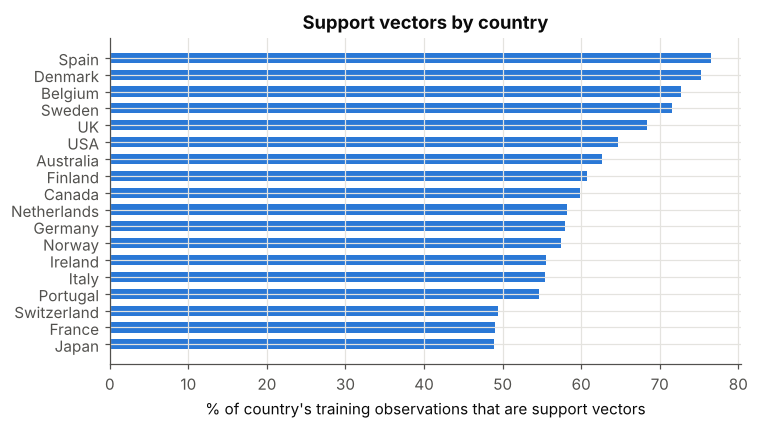

In [31]:
sv_country = (pd.DataFrame({"country": meta_train["country"].values, "SV": is_sv})
              .groupby("country")["SV"].mean().sort_values())
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(sv_country.index, sv_country.values * 100, color=C_NO, height=0.6)
ax.set_xlabel("% of country's training observations that are support vectors")
ax.set_title("Support vectors by country")
plt.tight_layout(); plt.show()

### 5b. Feature Importance — through model coefficients

For a **linear** SVM, $f(x)=w^\top x+b$ on **standardised** features, so $w_j$ is directly comparable across features: a positive $w_j$ pushes toward "crisis", and $|w_j|$ measures importance. We use the best linear SVM from the grid search.

The RBF kernel has no explicit **w** (it lives in an infinite-dimensional space), so for the tuned non-linear model we use **permutation importance** (drop in test AUROC when a feature is shuffled) as a complement.

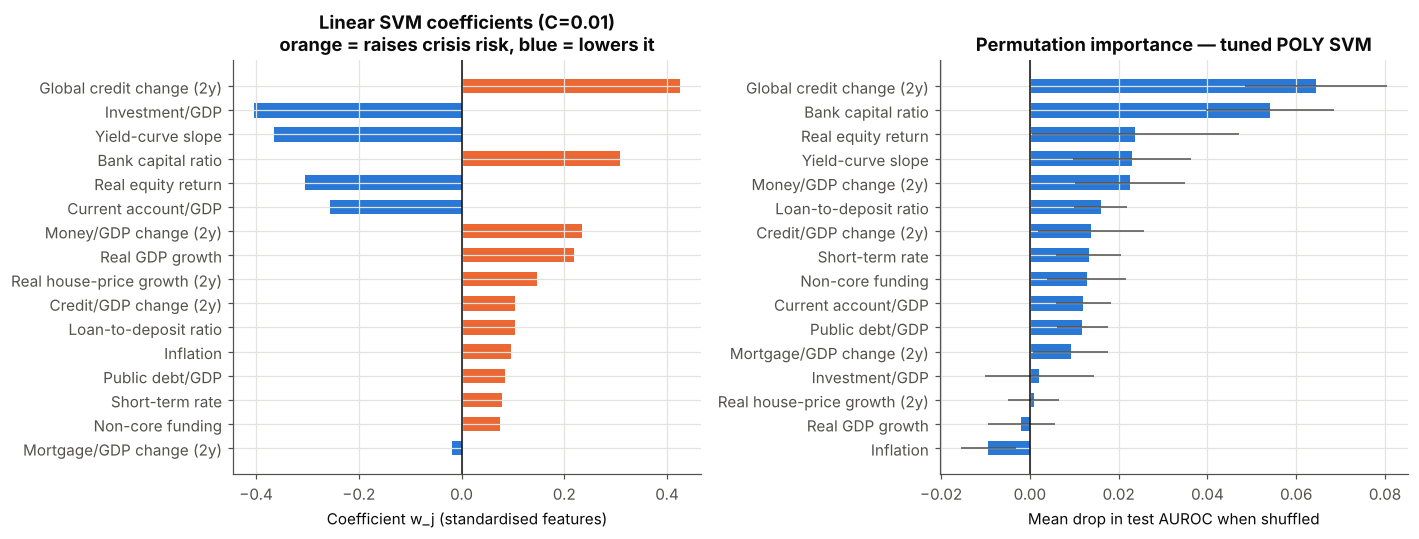

,linear w,|w| rank,perm. importance,perm. rank
Global credit change (2y),0.4251,1,0.0645,1
Investment/GDP,-0.4038,2,0.0021,13
Yield-curve slope,-0.3648,3,0.0231,4
Bank capital ratio,0.3088,4,0.0541,2
Real equity return,-0.3044,5,0.0238,3
Current account/GDP,-0.2565,6,0.0120,10
Money/GDP change (2y),0.2354,7,0.0225,5
Real GDP growth,0.2192,8,-0.0019,15
Real house-price growth (2y),0.1475,9,0.0009,14
Credit/GDP change (2y),0.1049,10,0.0137,7


In [32]:
best_lin_C = gs[gs["param_svm__kernel"] == "linear"].sort_values("mean_test_AUROC", ascending=False)["param_svm__C"].iloc[0]
lin_best = svm_pipeline(kernel="linear", C=best_lin_C).fit(X_train, y_train)
coef = pd.Series(lin_best.named_steps["svm"].coef_.ravel(), index=FEATURES)
coef_sorted = coef.reindex(coef.abs().sort_values().index)

perm = permutation_importance(best_model, X_test, y_test, scoring="roc_auc", n_repeats=30,
                              random_state=RANDOM_STATE, n_jobs=-1)
perm_s = pd.Series(perm.importances_mean, index=FEATURES).sort_values()
perm_sd = pd.Series(perm.importances_std, index=FEATURES).reindex(perm_s.index)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].barh([FEATURE_LABELS[f] for f in coef_sorted.index], coef_sorted.values,
             color=[C_YES if v > 0 else C_NO for v in coef_sorted.values], height=0.6)
axes[0].axvline(0, color=INK, lw=1)
axes[0].set_xlabel("Coefficient w_j (standardised features)")
axes[0].set_title(f"Linear SVM coefficients (C={best_lin_C})\norange = raises crisis risk, blue = lowers it")

axes[1].barh([FEATURE_LABELS[f] for f in perm_s.index], perm_s.values, xerr=perm_sd.values,
             color=C_NO, height=0.6, error_kw=dict(ecolor=INK2, lw=1))
axes[1].axvline(0, color=INK, lw=1)
axes[1].set_xlabel("Mean drop in test AUROC when shuffled")
axes[1].set_title(f"Permutation importance — tuned {grid.best_params_['svm__kernel'].upper()} SVM")
plt.tight_layout(); plt.show()

imp = pd.DataFrame({"linear w": coef, "|w| rank": coef.abs().rank(ascending=False).astype(int),
                    "perm. importance": perm_s.reindex(FEATURES),
                    "perm. rank": perm_s.reindex(FEATURES).rank(ascending=False).astype(int)})
imp.index = [FEATURE_LABELS[f] for f in imp.index]
imp.sort_values("|w| rank").round(4)

### 5c. Decision Boundary Visualisation — 2D and 3D cases

A 16-dimensional boundary can't be drawn, so we refit SVMs on the **two most important features** (2D) and the **three most important** (3D). These are illustrative models; the full model uses all 16 features.

**2D:** solid line = decision boundary $f(x)=0$; dashed lines = margins $f(x)=\pm1$; circled points = support vectors. The grid also illustrates the hyperparameter slide — effect of kernel, C and γ.

Top-2 features (by |w|): ['Global credit change (2y)', 'Investment/GDP']
Top-3 features: ['Global credit change (2y)', 'Investment/GDP', 'Yield-curve slope']


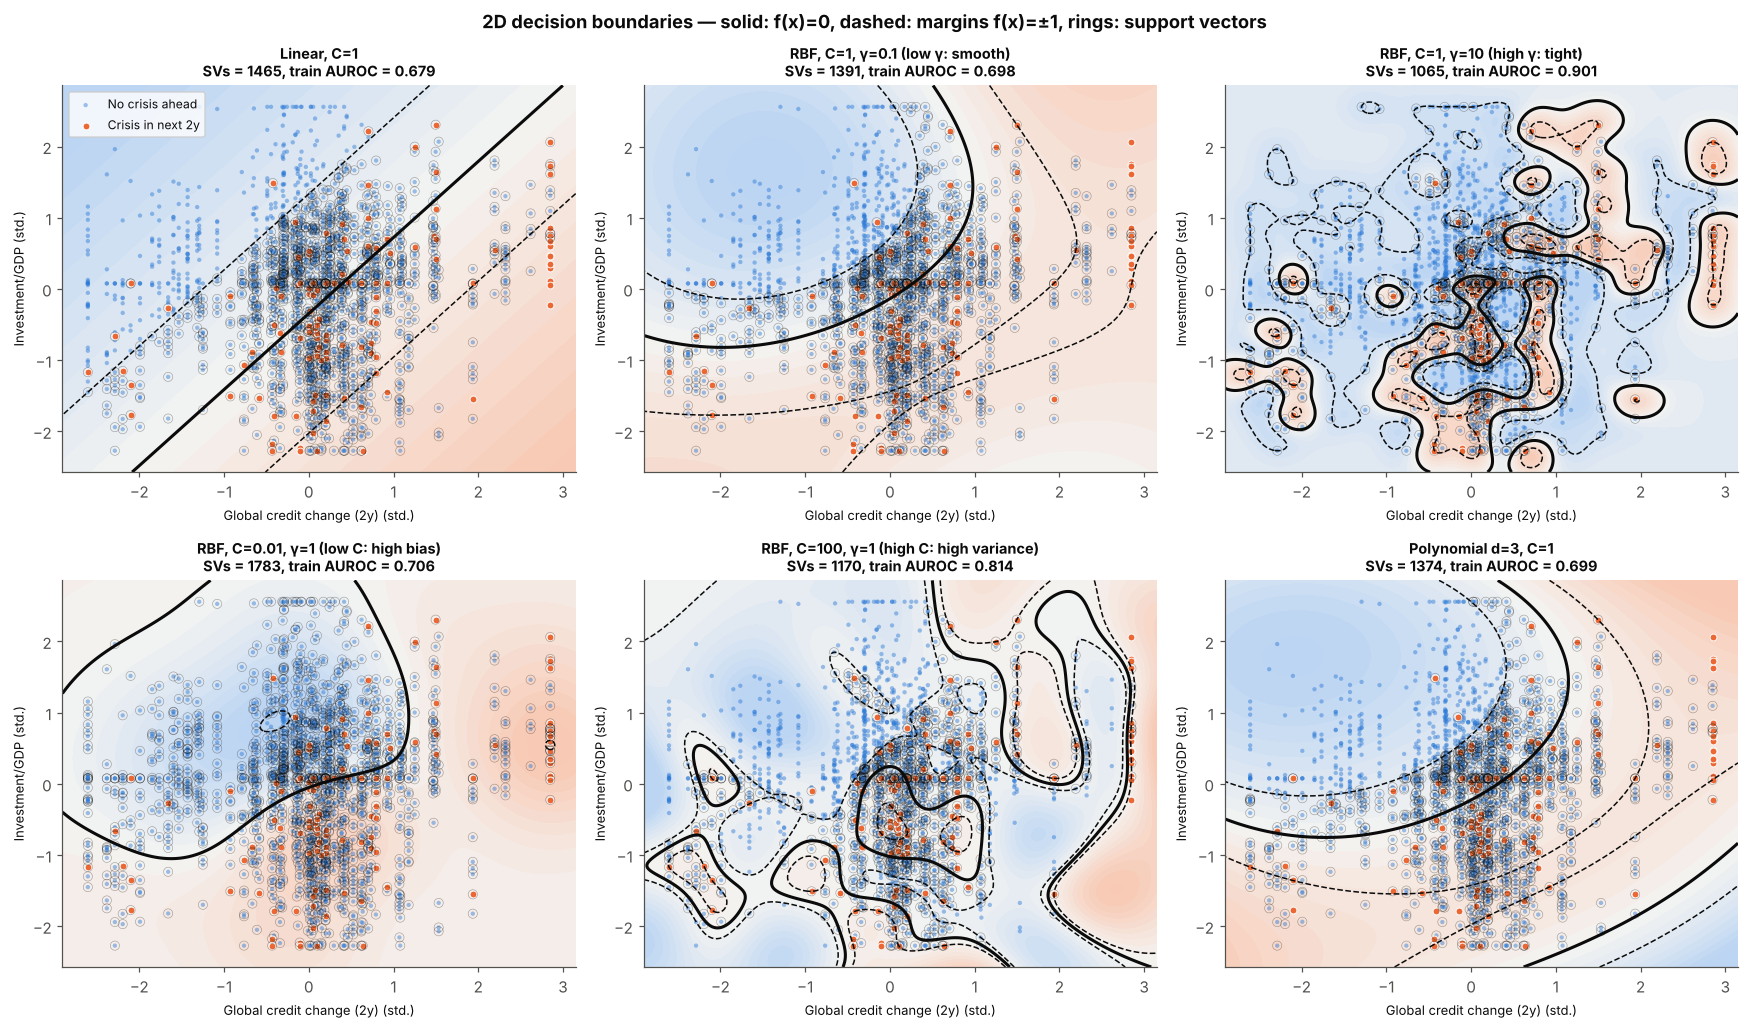

In [33]:
top3 = coef.abs().sort_values(ascending=False).index[:3].tolist()
f1_, f2_ = top3[:2]
print("Top-2 features (by |w|):", [FEATURE_LABELS[f] for f in (f1_, f2_)])
print("Top-3 features:", [FEATURE_LABELS[f] for f in top3])

pre2 = Pipeline(make_preprocessor()).fit(X_train[[f1_, f2_]])
Z2 = pre2.transform(X_train[[f1_, f2_]])
y2 = y_train.values
lo, hi = np.percentile(Z2, 0.5, axis=0) - 0.3, np.percentile(Z2, 99.5, axis=0) + 0.3
xx, yy = np.meshgrid(np.linspace(lo[0], hi[0], 300), np.linspace(lo[1], hi[1], 300))
grid_pts = np.c_[xx.ravel(), yy.ravel()]
div_cmap = sns.blend_palette(["#bcd5f3", "#f4f4f2", "#f8c9b4"], as_cmap=True)

configs = [("Linear, C=1", dict(kernel="linear", C=1)),
           ("RBF, C=1, γ=0.1 (low γ: smooth)", dict(kernel="rbf", C=1, gamma=0.1)),
           ("RBF, C=1, γ=10 (high γ: tight)", dict(kernel="rbf", C=1, gamma=10)),
           ("RBF, C=0.01, γ=1 (low C: high bias)", dict(kernel="rbf", C=0.01, gamma=1)),
           ("RBF, C=100, γ=1 (high C: high variance)", dict(kernel="rbf", C=100, gamma=1)),
           ("Polynomial d=3, C=1", dict(kernel="poly", degree=3, C=1, coef0=1))]

fig, axes = plt.subplots(2, 3, figsize=(16, 9.5))
for ax, (title, kw) in zip(axes.ravel(), configs):
    m = SVC(class_weight="balanced", **kw).fit(Z2, y2)
    Zf = m.decision_function(grid_pts).reshape(xx.shape)
    lim = np.percentile(np.abs(Zf), 98)
    ax.contourf(xx, yy, Zf, levels=np.linspace(-lim, lim, 21), cmap=div_cmap, extend="both")
    ax.contour(xx, yy, Zf, levels=[-1, 0, 1], colors=INK, linestyles=["--", "-", "--"], linewidths=[1, 2, 1])
    ax.scatter(*Z2[y2 == 0].T, s=8, c=C_NO, alpha=0.45, edgecolor="none", label="No crisis ahead")
    ax.scatter(*Z2[y2 == 1].T, s=20, c=C_YES, edgecolor="white", linewidth=0.6, label="Crisis in next 2y")
    sv = m.support_vectors_
    ax.scatter(sv[:, 0], sv[:, 1], s=36, facecolor="none", edgecolor=INK, linewidth=0.4, alpha=0.35)
    auc2 = roc_auc_score(y2, m.decision_function(Z2))
    ax.set_title(f"{title}\nSVs = {len(sv)}, train AUROC = {auc2:.3f}", fontsize=9.5)
    ax.set_xlim(lo[0], hi[0]); ax.set_ylim(lo[1], hi[1]); ax.grid(False)
    ax.set_xlabel(FEATURE_LABELS[f1_] + " (std.)", fontsize=8.5); ax.set_ylabel(FEATURE_LABELS[f2_] + " (std.)", fontsize=8.5)
axes[0, 0].legend(frameon=True, fontsize=8, loc="upper left")
fig.suptitle("2D decision boundaries — solid: f(x)=0, dashed: margins f(x)=±1, rings: support vectors",
             fontweight="bold")
plt.tight_layout(); plt.show()

**3D case:** a linear SVM on the top-3 features. The boundary $w_1x_1+w_2x_2+w_3x_3+b=0$ is a **plane**; we solve it for the third coordinate and draw it as a surface.

3D linear SVM:  w = [ 0.507 -0.455 -0.475]  b = -0.172 | train AUROC = 0.721


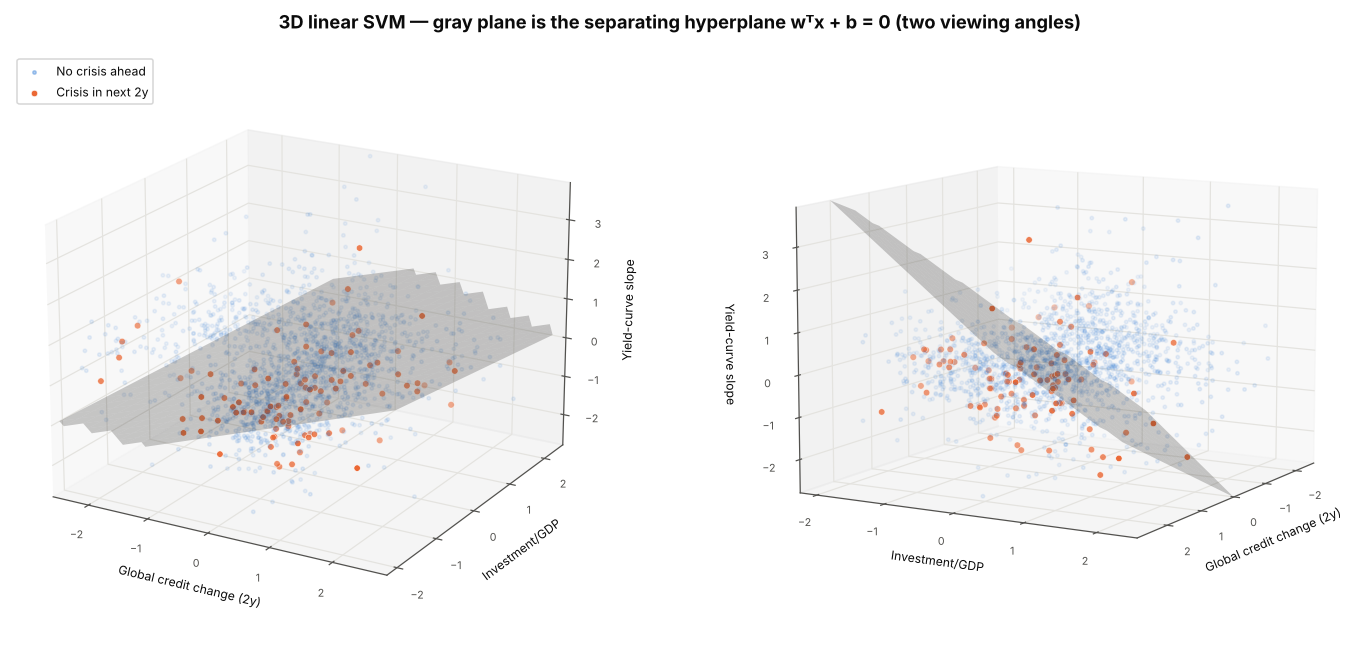

In [34]:
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401

pre3 = Pipeline(make_preprocessor()).fit(X_train[top3])
Z3 = pre3.transform(X_train[top3])
m3 = SVC(kernel="linear", C=best_lin_C, class_weight="balanced").fit(Z3, y2)
w3, b3 = m3.coef_.ravel(), m3.intercept_[0]
print("3D linear SVM:  w =", w3.round(3), " b =", round(b3, 3),
      f"| train AUROC = {roc_auc_score(y2, m3.decision_function(Z3)):.3f}")

# solve w1*x + w2*y + w3*z + b = 0 for the feature with the largest |w| -> stable surface
k = int(np.argmax(np.abs(w3))); others = [i for i in range(3) if i != k]
lo3, hi3 = np.percentile(Z3, 1, axis=0), np.percentile(Z3, 99, axis=0)
A, B = np.meshgrid(np.linspace(lo3[others[0]], hi3[others[0]], 25), np.linspace(lo3[others[1]], hi3[others[1]], 25))
C_ = -(w3[others[0]] * A + w3[others[1]] * B + b3) / w3[k]
P = [None] * 3; P[others[0]], P[others[1]], P[k] = A, B, C_

fig = plt.figure(figsize=(14, 6))
for j, (elev, azim) in enumerate([(20, -60), (10, 30)]):
    ax = fig.add_subplot(1, 2, j + 1, projection="3d")
    mask = np.all((Z3 > lo3) & (Z3 < hi3), axis=1)
    ax.scatter(*Z3[mask & (y2 == 0)].T, s=5, c=C_NO, alpha=0.35, label="No crisis ahead")
    ax.scatter(*Z3[mask & (y2 == 1)].T, s=18, c=C_YES, edgecolor="white", linewidth=0.4, label="Crisis in next 2y")
    P_clip = [np.clip(p, lo3[i], hi3[i]) if i == k else p for i, p in enumerate(P)]
    surf_mask = (C_ < lo3[k]) | (C_ > hi3[k])
    Pk = np.where(surf_mask, np.nan, P[k]); P_draw = [p if i != k else Pk for i, p in enumerate(P)]
    ax.plot_surface(*P_draw, color="#52514e", alpha=0.25, linewidth=0)
    ax.set_xlabel(FEATURE_LABELS[top3[0]], fontsize=8); ax.set_ylabel(FEATURE_LABELS[top3[1]], fontsize=8)
    ax.set_zlabel(FEATURE_LABELS[top3[2]], fontsize=8)
    ax.set_xlim(lo3[0], hi3[0]); ax.set_ylim(lo3[1], hi3[1]); ax.set_zlim(lo3[2], hi3[2])
    ax.view_init(elev=elev, azim=azim); ax.tick_params(labelsize=7)
    if j == 0: ax.legend(fontsize=8, loc="upper left")
fig.suptitle("3D linear SVM — gray plane is the separating hyperplane wᵀx + b = 0 (two viewing angles)", fontweight="bold")
plt.tight_layout(); plt.show()

Finally, the 3D boundary of the **RBF** kernel is a curved surface; we show it as slices of $f(x)=0$ in the plane of the top-2 features at low / mean / high values of the third feature.

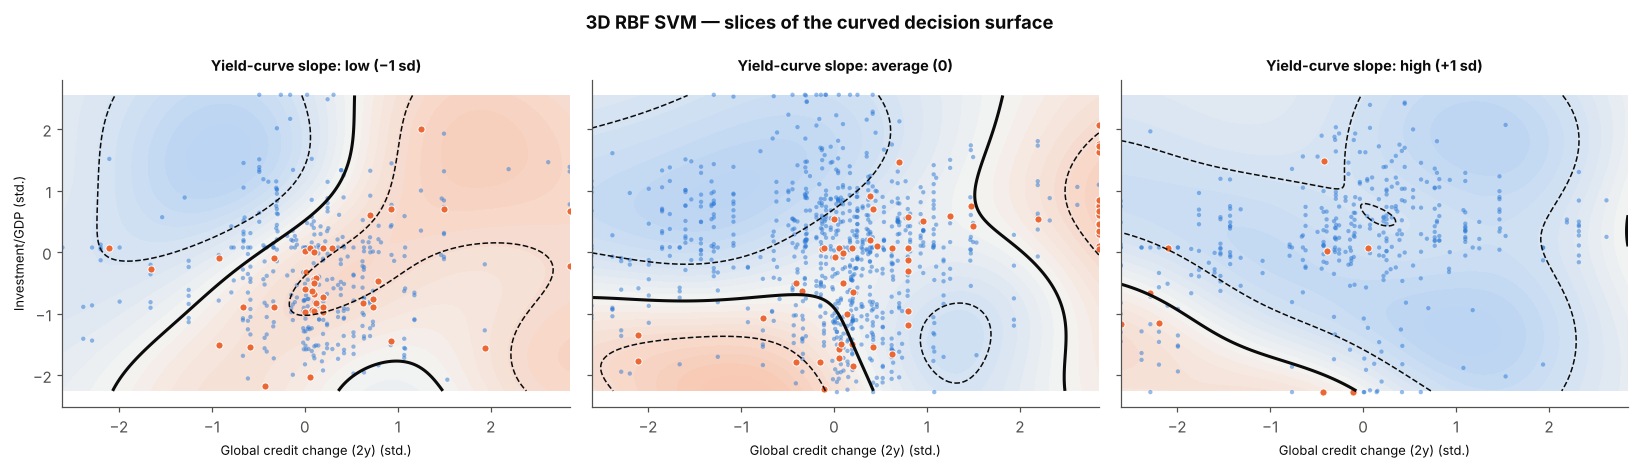

In [35]:
m3r = SVC(kernel="rbf", C=1, gamma=0.3, class_weight="balanced").fit(Z3, y2)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), sharey=True)
xx3, yy3 = np.meshgrid(np.linspace(lo3[0], hi3[0], 200), np.linspace(lo3[1], hi3[1], 200))
for ax, zval, lab in zip(axes, [-1, 0, 1], ["low (−1 sd)", "average (0)", "high (+1 sd)"]):
    pts = np.c_[xx3.ravel(), yy3.ravel(), np.full(xx3.size, zval)]
    Zf = m3r.decision_function(pts).reshape(xx3.shape)
    lim = np.percentile(np.abs(Zf), 98)
    ax.contourf(xx3, yy3, Zf, levels=np.linspace(-lim, lim, 21), cmap=div_cmap, extend="both")
    ax.contour(xx3, yy3, Zf, levels=[-1, 0, 1], colors=INK, linestyles=["--", "-", "--"], linewidths=[1, 2, 1])
    near = np.abs(Z3[:, 2] - zval) < 0.5
    ax.scatter(*Z3[near & (y2 == 0), :2].T, s=8, c=C_NO, alpha=0.5, edgecolor="none")
    ax.scatter(*Z3[near & (y2 == 1), :2].T, s=22, c=C_YES, edgecolor="white", linewidth=0.6)
    ax.set_title(f"{FEATURE_LABELS[top3[2]]}: {lab}", fontsize=9.5); ax.grid(False)
    ax.set_xlabel(FEATURE_LABELS[top3[0]] + " (std.)", fontsize=8.5)
axes[0].set_ylabel(FEATURE_LABELS[top3[1]] + " (std.)", fontsize=8.5)
fig.suptitle("3D RBF SVM — slices of the curved decision surface", fontweight="bold")
plt.tight_layout(); plt.show()

---
## Summary

In [36]:
best_test = evaluate(best_model, X_test, y_test)
print("=" * 70)
print("SVM FINANCIAL-CRISIS EARLY-WARNING MODEL — SUMMARY")
print("=" * 70)
print(f"Data         : JST Macrohistory R6, {raw['country'].nunique()} countries, {raw['year'].min()}-{raw['year'].max()}")
print(f"Sample       : {len(model_df)} country-years, {len(FEATURES)} engineered features, "
      f"{model_df[TARGET].mean():.1%} positives")
print(f"Best model   : {grid.best_params_}  (5-fold CV AUROC = {grid.best_score_:.3f})")
print("Test metrics : " + ", ".join(f"{k} = {v:.3f}" for k, v in best_test.items()))
print(f"Support vecs : {best_svc.n_support_.sum()} of {len(y_train)} training points ({best_svc.n_support_.sum()/len(y_train):.1%})")
print("Top drivers  : " + ", ".join(FEATURE_LABELS[f] for f in coef.abs().sort_values(ascending=False).index[:5]))
print(f"SVR (ltrate) : MSE = {reg_metrics['MSE']:.3f}, MAE = {reg_metrics['MAE']:.3f}, R² = {reg_metrics['R²']:.3f}")

SVM FINANCIAL-CRISIS EARLY-WARNING MODEL — SUMMARY
Data         : JST Macrohistory R6, 18 countries, 1870-2020
Sample       : 2250 country-years, 16 engineered features, 7.4% positives
Best model   : {'svm__C': 0.1, 'svm__coef0': 1, 'svm__degree': 2, 'svm__gamma': 'scale', 'svm__kernel': 'poly'}  (5-fold CV AUROC = 0.824)
Test metrics : Accuracy = 0.711, Precision = 0.161, Recall = 0.697, F1 = 0.261, AUROC = 0.760
Support vecs : 1102 of 1800 training points (61.2%)
Top drivers  : Global credit change (2y), Investment/GDP, Yield-curve slope, Bank capital ratio, Real equity return
SVR (ltrate) : MSE = 3.539, MAE = 1.021, R² = 0.661


### Key takeaways
1. **Data preparation** dominated the work: nominal series had to be turned into ratios/growth rates, war-time outliers removed, and winsorising + median imputation + standardisation placed *inside* the pipeline so CV is leak-free.
2. **Model selection:** non-linear kernels fit training data more closely; the linear kernel generalises with a small train–test gap. Grid search picks the configuration with the best cross-validated AUROC.
3. **Training:** the dual solution gives α; we verified $w=\sum\alpha_i y_i x_i$ and $f(x)=w^\top x+b$ numerically, and stored w, b and support vectors to disk.
4. **Validation:** accuracy is misleading with ~8% positives — recall, precision, F1 and AUROC tell the real story.
5. **Hyperparameters:** low C / low γ → smooth, high-bias models; high C / high γ → training AUROC → 1 but CV AUROC falls (overfitting).
6. **Interpretation:** the strongest signals are **global credit booms**, a **flat or inverted yield curve** (negative slope weight), fast **money/credit growth**, and weak **real equity returns**. These match the macro-finance literature on crisis prediction. Higher investment/GDP and current-account surpluses lower predicted risk. The positive weight on the bank capital ratio mostly reflects history: 19th-century banks held more capital *and* crises were more frequent, so this is a correlation, not a causal effect.
7. **Support vectors:** more than half of the training points are SVs, a sign that the classes overlap heavily. They include almost every pre-crisis year plus "near-miss" boom years that did *not* end in crisis (e.g. Japan in the early 1930s, Australia 2008). These near-misses produce the false alarms.